# Capstone Gate 3: Athlete Readiness (EDA)
Can we turn **Recovery_Score** (0 to 100) into 3 tiers: Green, Orange, Red?

In [1]:
# Import the libraries we need
import pandas as pd                 
import numpy as np                  
import matplotlib.pyplot as plt     
import seaborn as sns               
from sklearn.model_selection import train_test_split   
from sklearn.linear_model import LinearRegression    
from sklearn.metrics import mean_absolute_error, r2_score 

## Part A: Look at the Data

In [2]:
# Load the CSV file
df = pd.read_csv("athlete_recovery_synthetic.csv")

# Show the first 5 rows
print(df.head(5))

print("Shape:", df.shape)
print("Number of athletes:", df["Athlete_ID"].nunique())

   Athlete_ID  Day  Day_of_Week  Week  Age Gender  Sport_Type Training_Type  \
0        1000    1            1     1   28   Male  Team Sport          HIIT   
1        1000    2            2     1   28   Male  Team Sport        Cardio   
2        1000    3            3     1   28   Male  Team Sport          HIIT   
3        1000    4            4     1   28   Male  Team Sport        Cardio   
4        1000    5            5     1   28   Male  Team Sport          HIIT   

   Training_Duration_Min  Training_Intensity  Sleep_Duration_Hours  \
0                     46                 7.9                   7.7   
1                     71                 7.0                   7.3   
2                     45                 7.3                   7.7   
3                     86                 7.5                   7.9   
4                     28                 9.2                   6.7   

   Caffeine_Intake_mg Stress_Level  Resting_Heart_Rate  HRV_ms  Mood_Score  \
0                 270     

In [3]:
# Missing values and duplicates
print(df.isna().sum())
print()
print("Duplicated rows:", df.duplicated().sum())

Athlete_ID                 0
Day                        0
Day_of_Week                0
Week                       0
Age                        0
Gender                     0
Sport_Type                 0
Training_Type              0
Training_Duration_Min      0
Training_Intensity         1
Sleep_Duration_Hours     604
Caffeine_Intake_mg         0
Stress_Level               0
Resting_Heart_Rate         0
HRV_ms                     0
Mood_Score                 0
Muscle_Soreness            0
Energy_Level               0
Recovery_Score             0
dtype: int64

Duplicated rows: 0


In [4]:
# Basic stats
print(df.describe())

        Athlete_ID          Day  Day_of_Week         Week          Age  \
count  8379.000000  8379.000000  8379.000000  8379.000000  8379.000000   
mean   1149.458647    14.497076     3.998329     2.499821    25.860962   
std      86.631832     8.078044     2.000417     1.117941     4.531092   
min    1000.000000     1.000000     1.000000     1.000000    18.000000   
25%    1074.000000     8.000000     2.000000     2.000000    23.000000   
50%    1149.000000    14.000000     4.000000     2.000000    26.000000   
75%    1224.000000    21.000000     6.000000     3.000000    28.000000   
max    1299.000000    28.000000     7.000000     4.000000    41.000000   

       Training_Duration_Min  Training_Intensity  Sleep_Duration_Hours  \
count            8379.000000         8378.000000           7775.000000   
mean               52.789712            6.211506              7.498842   
std                21.357704            2.368960              0.693790   
min                10.000000         

**Question:** Which data quality issues could make our model unreliable?

**Answer:**
- Sleep_Duration_Hours has 604 missing values (about 7%). Training_Intensity has only 1.
- There are 8,379 rows (not 8,400) and 300 athletes.
- No duplicates and no impossible values.
- The file is **synthetic**, so our results show the method works, not that it works on real athletes.

## Part B: The Target and the 3 Tiers

In [5]:
# Turn the score into a tier
def get_tier(score):
    if score >= 75:
        return "Green"
    elif score >= 40:
        return "Orange"
    else:
        return "Red"

df["Tier"] = df["Recovery_Score"].apply(get_tier)

# Count and percent of each tier
print(df["Tier"].value_counts())
print((df["Tier"].value_counts(normalize=True) * 100).round(1))

Tier
Orange    3446
Red       3255
Green     1678
Name: count, dtype: int64
Tier
Orange    41.1
Red       38.8
Green     20.0
Name: proportion, dtype: float64


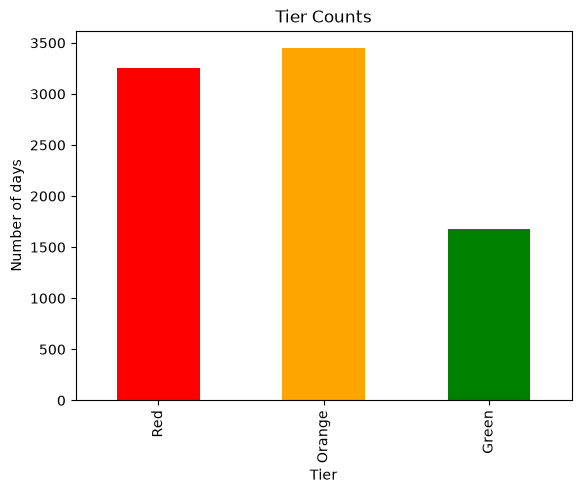

In [6]:
# Bar chart of the tiers
df["Tier"].value_counts().reindex(["Red", "Orange", "Green"]).plot(kind="bar", color=["red", "orange", "green"])
plt.ylabel("Number of days")
plt.title("Tier Counts")
plt.show()

**Answer:** *Are the tiers balanced?*

Not fully. Red is about 39%, Orange about 41% and Green only about 20%. Red is not rare, so the model will have plenty of Red examples. Because of this, we will not judge the model by accuracy alone.

## Part C: What Is Related to Recovery Score?

Recovery_Score           1.000000
HRV_ms                   0.827900
Energy_Level             0.682012
Sleep_Duration_Hours     0.616461
Mood_Score               0.559228
Day_of_Week              0.054942
Training_Duration_Min   -0.064701
Day                     -0.141646
Week                    -0.160260
Caffeine_Intake_mg      -0.201344
Age                     -0.224721
Training_Intensity      -0.317917
Resting_Heart_Rate      -0.412741
Muscle_Soreness         -0.501687
Name: Recovery_Score, dtype: float64


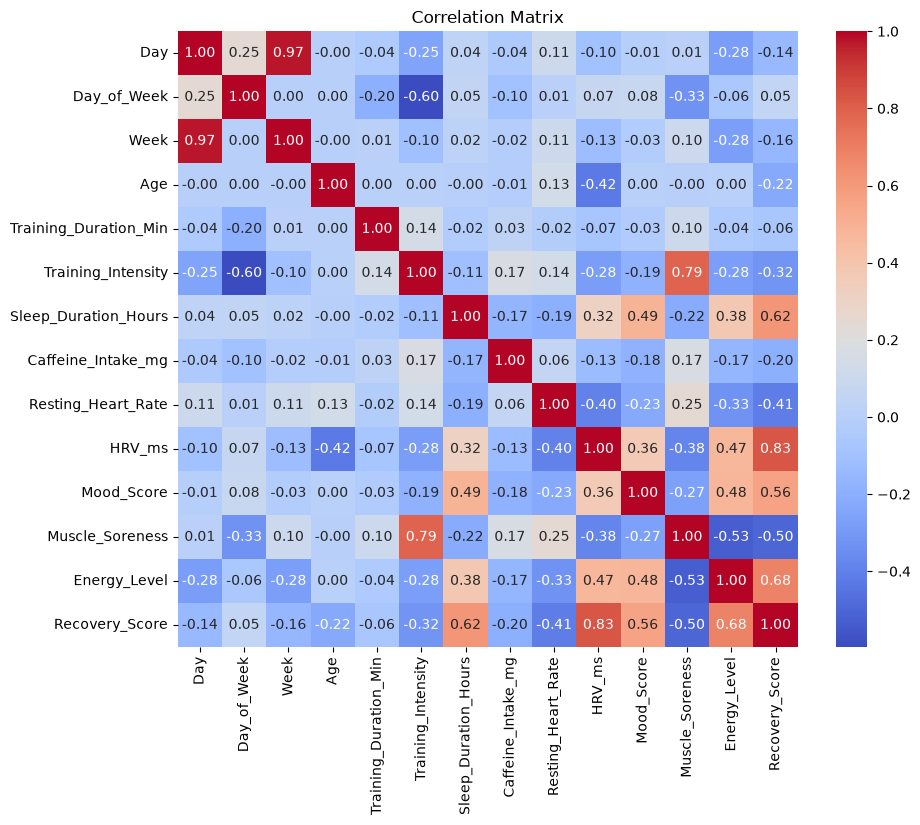

In [7]:
# Correlation of each number column with Recovery_Score, highest first
corr = df.drop(columns=["Athlete_ID"]).corr(numeric_only=True)
print(corr["Recovery_Score"].sort_values(ascending=False))

# Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

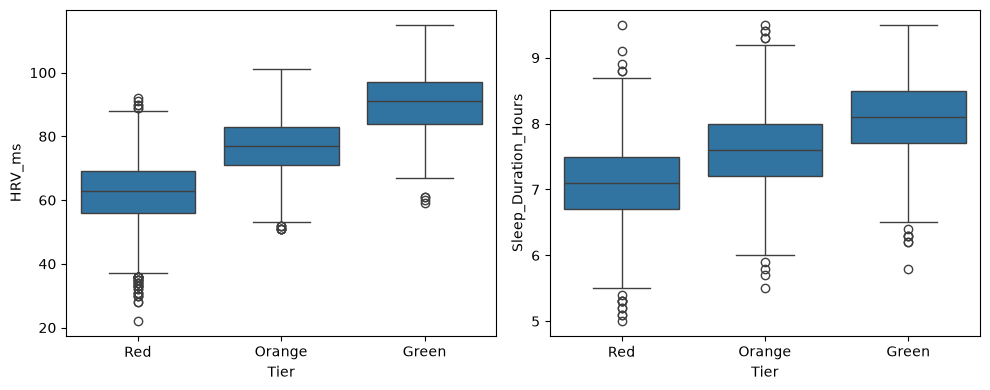

In [8]:
# Boxplots: HRV and Sleep for each tier
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(data=df, x="Tier", y="HRV_ms", order=["Red", "Orange", "Green"], ax=axes[0])
sns.boxplot(data=df, x="Tier", y="Sleep_Duration_Hours", order=["Red", "Orange", "Green"], ax=axes[1])
plt.tight_layout()
plt.show()

**Answer:** *Which columns matter most?*

HRV is the strongest (about 0.83), then Sleep (about 0.62). Muscle soreness (about -0.50) and resting heart rate (about -0.41) go the other way: higher means lower recovery. The boxplots agree: Green days have higher HRV and sleep.

**Careful:** Mood (about 0.56) and Energy (about 0.68) are also strong, but they describe how the athlete feels, so they may be a result of recovery, not a cause. We should leave them out of the first model.

## Part D: Is the Missing Sleep Random?

In [9]:
# Average recovery when sleep is missing vs not missing
sleep_missing = df["Sleep_Duration_Hours"].isna()
print(df.groupby(sleep_missing)["Recovery_Score"].mean().round(1))

Sleep_Duration_Hours
False    50.6
True     28.8
Name: Recovery_Score, dtype: float64


**Answer:** Days with missing sleep have a much lower average recovery (about 29) than days with sleep recorded (about 51). So the missing values are **not random**: the missing sleep itself is a clue.

**Plan:** when we clean the data, we should fill the blanks and also add a "sleep missing" column (1 or 0).

## Summary

| Item | Result |
|---|---|
| Source | Kaggle, athlete_recovery_synthetic (synthetic data) |
| Size | 8,379 rows, 300 athletes, 25 to 28 days each |
| Target | Recovery_Score turned into Green (75+), Orange (40 to 74), Red (under 40) |
| Tier split | Red about 39%, Orange about 41%, Green about 20% |
| Missing | Sleep 604 (not random), Training_Intensity 1 |
| Strongest links | HRV, Sleep, Muscle soreness, Resting heart rate |
| Watch out | Mood and Energy may leak; missing sleep is a clue |
| Limitation | Synthetic data |